<a href="https://colab.research.google.com/github/robertrheman-spec/pore-pressure-calculatior/blob/main/Reservoir_Performance_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Reservoir Engineering Model Initialized")

Reservoir Engineering Model Initialized


In [2]:
# RESERVOIR INPUT PARAMETERS

reservoir = {
    "Initial_Pressure_bar": 300,
    "Bubble_Point_bar": 250,
    "Temperature_C": 90,
    "OOIP_STB": 10_000_000,
    "Oil_FVF": 1.25,
    "Solution_GOR_scf_STB": 100,
    "Porosity": 0.20,
    "Water_Saturation": 0.20,
    "Oil_Compressibility": 1.2e-4,
    "Rock_Compressibility": 3.0e-5,
    "Water_Compressibility": 4.5e-4,
    "Oil_Production_Rate_STB_day": 1000
}

for key, value in reservoir.items():
    print(f"{key}: {value}")

Initial_Pressure_bar: 300
Bubble_Point_bar: 250
Temperature_C: 90
OOIP_STB: 10000000
Oil_FVF: 1.25
Solution_GOR_scf_STB: 100
Porosity: 0.2
Water_Saturation: 0.2
Oil_Compressibility: 0.00012
Rock_Compressibility: 3e-05
Water_Compressibility: 0.00045
Oil_Production_Rate_STB_day: 1000


In [3]:
# EFFECTIVE RESERVOIR COMPRESSIBILITY

co = reservoir["Oil_Compressibility"]
cf = reservoir["Rock_Compressibility"]
cw = reservoir["Water_Compressibility"]
Swi = reservoir["Water_Saturation"]

ce = co + (cf + Swi * cw) / (1 - Swi)

print(f"Effective Compressibility = {ce:.6f} 1/bar")

Effective Compressibility = 0.000270 1/bar


In [39]:
# RESERVOIR PRESSURE DECLINE MODEL

Pi = reservoir["Initial_Pressure_bar"]
OOIP = reservoir["OOIP_STB"]
qo = reservoir["Oil_Production_Rate_STB_day"]
Pb = reservoir["Bubble_Point_bar"]

# Simulation time in days
time = np.arange(0, 136, 1)

# Cumulative oil production
Np = qo * time

# Reservoir pressure
pressure = Pi - Np / (OOIP * ce)

# Stop at bubble point
pressure = np.maximum(pressure, Pb)

print("Pressure depletion calculation completed.")
print(f"Initial Pressure: {pressure[0]:.2f} bar")
print(f"Pressure after 100 days: {pressure[100]:.2f} bar")
print(f"Final Pressure: {pressure[-1]:.2f} bar")

Pressure depletion calculation completed.
Initial Pressure: 300.00 bar
Pressure after 100 days: 262.96 bar
Final Pressure: 250.00 bar


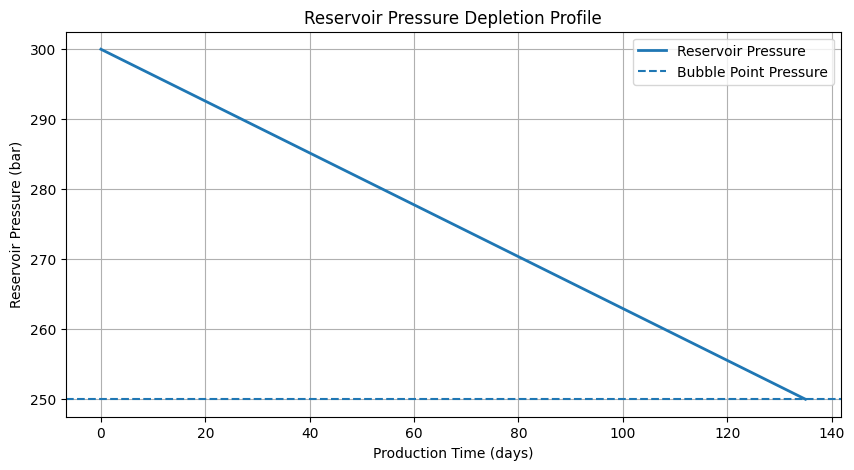

In [5]:
# RESERVOIR PRESSURE DECLINE PLOT

plt.figure(figsize=(10, 5))

plt.plot(time, pressure, linewidth=2, label="Reservoir Pressure")

plt.axhline(
    y=Pb,
    linestyle="--",
    label="Bubble Point Pressure"
)

plt.xlabel("Production Time (days)")
plt.ylabel("Reservoir Pressure (bar)")
plt.title("Reservoir Pressure Depletion Profile")

plt.legend()
plt.grid(True)
plt.show()

In [6]:
# RECOVERY FACTOR CALCULATION

RF = (Np / OOIP) * 100

print(f"Initial Recovery Factor: {RF[0]:.2f}%")
print(f"Recovery Factor after 100 days: {RF[100]:.2f}%")
print(f"Recovery Factor at bubble point: {RF[-1]:.2f}%")

Initial Recovery Factor: 0.00%
Recovery Factor after 100 days: 1.00%
Recovery Factor at bubble point: 1.35%


In [7]:
# PRODUCTION PERFORMANCE DATA

results = pd.DataFrame({
    "Time_days": time,
    "Reservoir_Pressure_bar": pressure,
    "Oil_Rate_STB_day": np.full(len(time), qo),
    "Cumulative_Oil_STB": Np,
    "Recovery_Factor_percent": RF
})

display(results.head(10))

,Time_days,Reservoir_Pressure_bar,Oil_Rate_STB_day,Cumulative_Oil_STB,Recovery_Factor_percent
0,0,300.000000,1000,0,0.00
1,1,299.629630,1000,1000,0.01
2,2,299.259259,1000,2000,0.02
3,3,298.888889,1000,3000,0.03
4,4,298.518519,1000,4000,0.04
5,5,298.148148,1000,5000,0.05
6,6,297.777778,1000,6000,0.06
7,7,297.407407,1000,7000,0.07
8,8,297.037037,1000,8000,0.08
9,9,296.666667,1000,9000,0.09


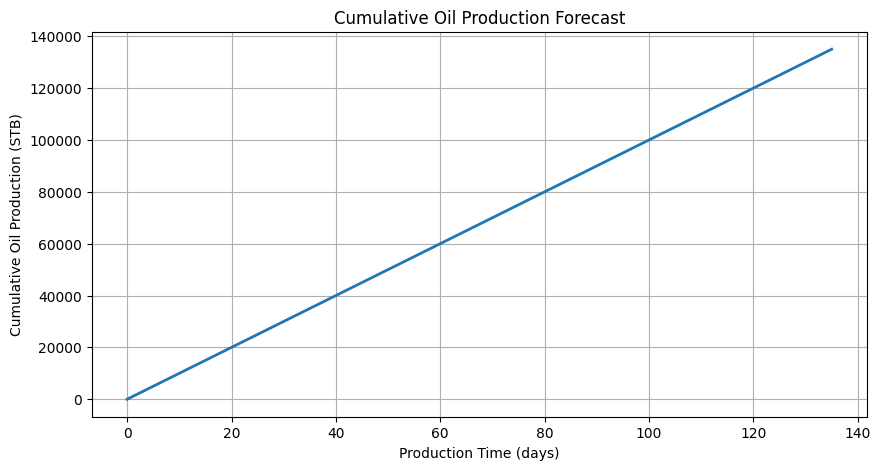

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(time, Np, linewidth=2)

plt.xlabel("Production Time (days)")
plt.ylabel("Cumulative Oil Production (STB)")
plt.title("Cumulative Oil Production Forecast")

plt.grid(True)
plt.show()

In [9]:
results.to_csv("Reservoir_Production_Data.csv", index=False)

print("Reservoir production data exported successfully!")

Reservoir production data exported successfully!


In [10]:
# GAS AND WATER PRODUCTION PARAMETERS

GOR = 100          # Producing gas-oil ratio (scf/STB)
water_cut = 0.20   # Water cut (20%)

# Calculate gas production
gas_rate = qo * GOR

# Calculate water production
water_rate = qo * water_cut / (1 - water_cut)

print(f"Oil production rate: {qo:.2f} STB/day")
print(f"Gas production rate: {gas_rate:,.2f} scf/day")
print(f"Water production rate: {water_rate:.2f} STB/day")

Oil production rate: 1000.00 STB/day
Gas production rate: 100,000.00 scf/day
Water production rate: 250.00 STB/day


In [11]:
# COMBINED PRODUCTION PROFILE

results["Oil_Rate_STB_day"] = qo
results["Gas_Rate_scf_day"] = gas_rate
results["Water_Rate_STB_day"] = water_rate

results["GOR_scf_STB"] = GOR
results["Water_Cut_percent"] = water_cut * 100

display(results.head(10))

,Time_days,Reservoir_Pressure_bar,Oil_Rate_STB_day,Cumulative_Oil_STB,Recovery_Factor_percent,Gas_Rate_scf_day,Water_Rate_STB_day,GOR_scf_STB,Water_Cut_percent
0,0,300.000000,1000,0,0.00,100000,250.0,100,20.0
1,1,299.629630,1000,1000,0.01,100000,250.0,100,20.0
2,2,299.259259,1000,2000,0.02,100000,250.0,100,20.0
3,3,298.888889,1000,3000,0.03,100000,250.0,100,20.0
4,4,298.518519,1000,4000,0.04,100000,250.0,100,20.0
5,5,298.148148,1000,5000,0.05,100000,250.0,100,20.0
6,6,297.777778,1000,6000,0.06,100000,250.0,100,20.0
7,7,297.407407,1000,7000,0.07,100000,250.0,100,20.0
8,8,297.037037,1000,8000,0.08,100000,250.0,100,20.0
9,9,296.666667,1000,9000,0.09,100000,250.0,100,20.0


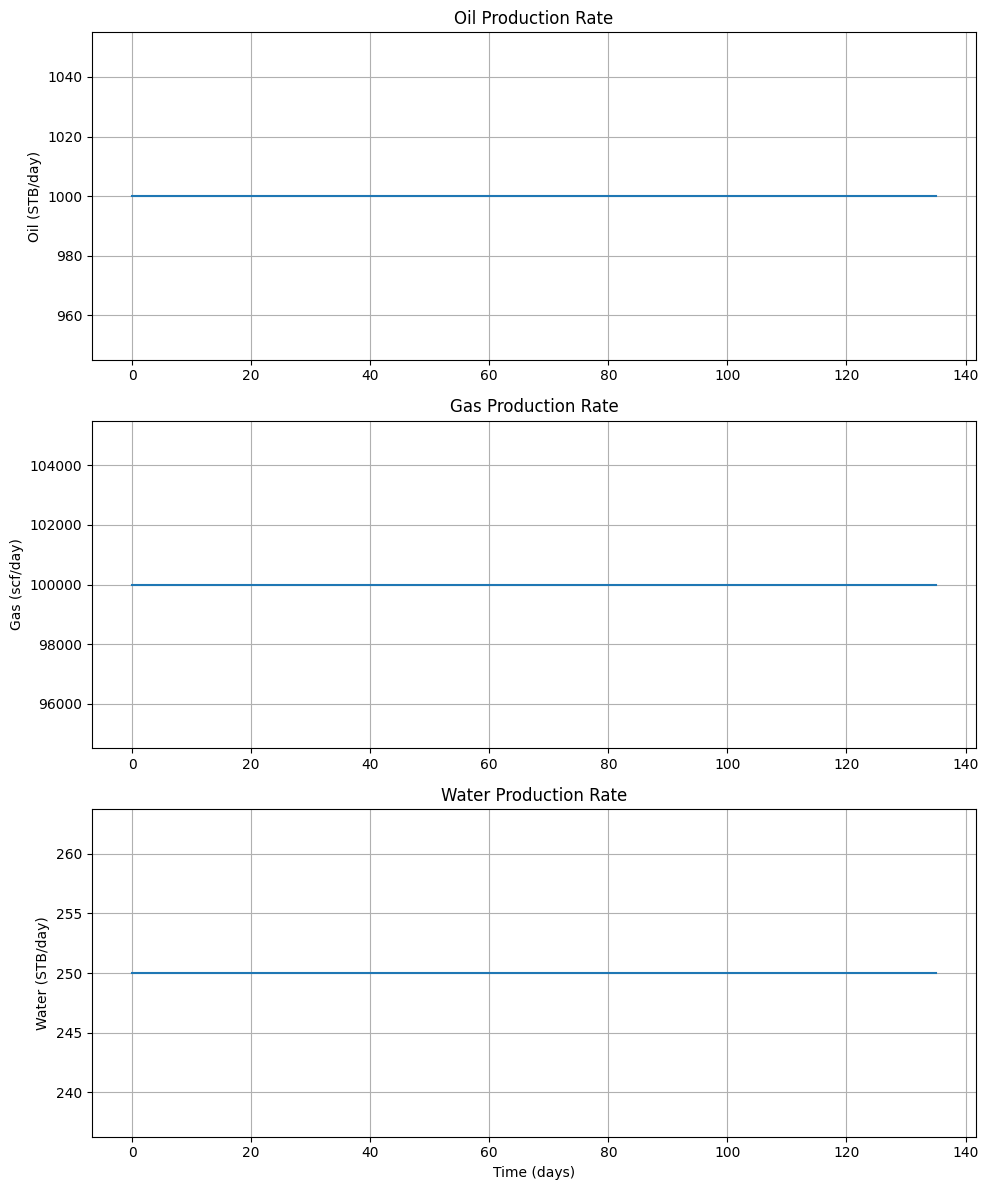

In [12]:
# COMBINED PRODUCTION PROFILE

fig, ax = plt.subplots(3, 1, figsize=(10, 12))

ax[0].plot(time, np.full(len(time), qo))
ax[0].set_title("Oil Production Rate")
ax[0].set_ylabel("Oil (STB/day)")
ax[0].grid()

ax[1].plot(time, np.full(len(time), gas_rate))
ax[1].set_title("Gas Production Rate")
ax[1].set_ylabel("Gas (scf/day)")
ax[1].grid()

ax[2].plot(time, np.full(len(time), water_rate))
ax[2].set_title("Water Production Rate")
ax[2].set_ylabel("Water (STB/day)")
ax[2].set_xlabel("Time (days)")
ax[2].grid()

plt.tight_layout()
plt.show()

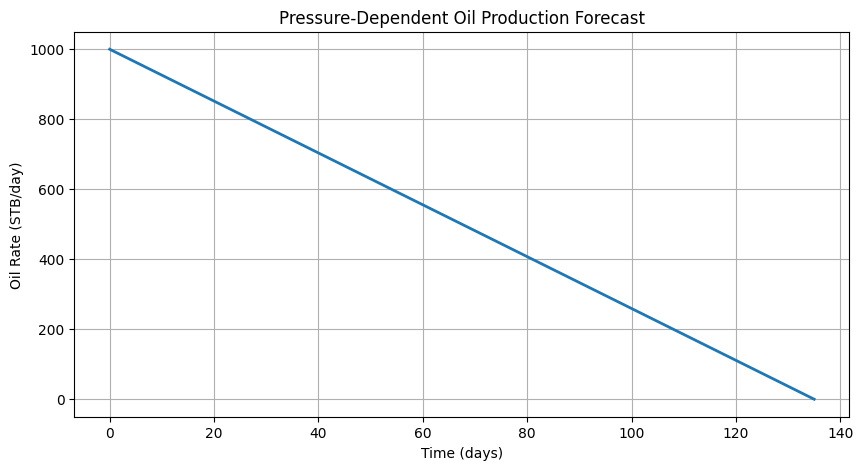

In [13]:
# PRESSURE-DEPENDENT PRODUCTION MODEL

q_initial = qo

# Simple linear productivity approximation
production_rate = q_initial * (pressure - Pb) / (Pi - Pb)

# Avoid negative production
production_rate = np.maximum(production_rate, 0)

plt.figure(figsize=(10, 5))

plt.plot(time, production_rate, linewidth=2)

plt.xlabel("Time (days)")
plt.ylabel("Oil Rate (STB/day)")
plt.title("Pressure-Dependent Oil Production Forecast")

plt.grid()
plt.show()

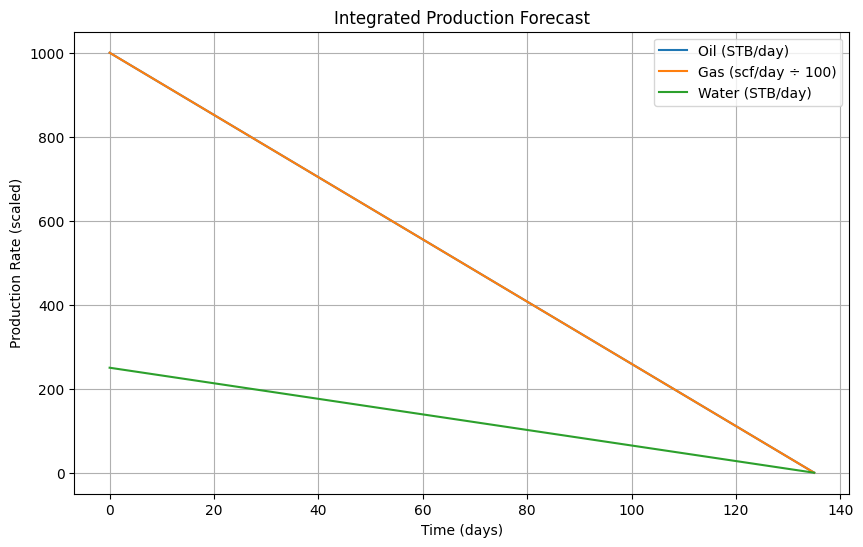

In [14]:
# PRESSURE-DEPENDENT OIL, GAS AND WATER RATES

oil_rate = production_rate

gas_rate_profile = oil_rate * GOR

water_rate_profile = oil_rate * water_cut / (1 - water_cut)

plt.figure(figsize=(10, 6))

plt.plot(time, oil_rate, label="Oil (STB/day)")
plt.plot(time, gas_rate_profile / 100, label="Gas (scf/day ÷ 100)")
plt.plot(time, water_rate_profile, label="Water (STB/day)")

plt.xlabel("Time (days)")
plt.ylabel("Production Rate (scaled)")
plt.title("Integrated Production Forecast")

plt.legend()
plt.grid()
plt.show()

In [15]:
# FINAL PRODUCTION DATASET

integrated_results = pd.DataFrame({
    "Time_days": time,
    "Reservoir_Pressure_bar": pressure,
    "Oil_Rate_STB_day": oil_rate,
    "Gas_Rate_scf_day": gas_rate_profile,
    "Water_Rate_STB_day": water_rate_profile,
    "Recovery_Factor_percent": RF
})

display(integrated_results.head(10))

,Time_days,Reservoir_Pressure_bar,Oil_Rate_STB_day,Gas_Rate_scf_day,Water_Rate_STB_day,Recovery_Factor_percent
0,0,300.000000,1000.000000,100000.000000,250.000000,0.00
1,1,299.629630,992.592593,99259.259259,248.148148,0.01
2,2,299.259259,985.185185,98518.518519,246.296296,0.02
3,3,298.888889,977.777778,97777.777778,244.444444,0.03
4,4,298.518519,970.370370,97037.037037,242.592593,0.04
5,5,298.148148,962.962963,96296.296296,240.740741,0.05
6,6,297.777778,955.555556,95555.555556,238.888889,0.06
7,7,297.407407,948.148148,94814.814815,237.037037,0.07
8,8,297.037037,940.740741,94074.074074,235.185185,0.08
9,9,296.666667,933.333333,93333.333333,233.333333,0.09


In [16]:
# EXPORT INTEGRATED RESERVOIR DATA

integrated_results.to_csv(
    "Integrated_Reservoir_Production.csv",
    index=False
)

print("Integrated reservoir production data exported successfully!")

Integrated reservoir production data exported successfully!


In [17]:
from google.colab import files

files.download("Integrated_Reservoir_Production.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# LOAD THE EXPORTED PRODUCTION DATA

from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv("Integrated_Reservoir_Production.csv")

display(df.head())

,Time_days,Reservoir_Pressure_bar,Oil_Rate_STB_day,Gas_Rate_scf_day,Water_Rate_STB_day,Recovery_Factor_percent
0,0,300.000000,1000.000000,100000.000000,250.000000,0.00
1,1,299.629630,992.592593,99259.259259,248.148148,0.01
2,2,299.259259,985.185185,98518.518519,246.296296,0.02
3,3,298.888889,977.777778,97777.777778,244.444444,0.03
4,4,298.518519,970.370370,97037.037037,242.592593,0.04


In [19]:
# EXTRACT DAY 0 RESERVOIR CONDITIONS

day0 = df.iloc[0]

print("DAY 0 RESERVOIR CONDITIONS")
print("--------------------------")
print("Reservoir Pressure:", day0["Reservoir_Pressure_bar"], "bar")
print("Oil Rate:", day0["Oil_Rate_STB_day"], "STB/day")
print("Gas Rate:", day0["Gas_Rate_scf_day"], "scf/day")
print("Water Rate:", day0["Water_Rate_STB_day"], "STB/day")
print("Recovery Factor:", day0["Recovery_Factor_percent"], "%")

DAY 0 RESERVOIR CONDITIONS
--------------------------
Reservoir Pressure: 300.0 bar
Oil Rate: 1000.0 STB/day
Gas Rate: 100000.0 scf/day
Water Rate: 250.0 STB/day
Recovery Factor: 0.0 %


In [20]:
# PRODUCTION RATE CONVERSION

# Constants
STB_to_m3 = 0.158987
scf_to_m3 = 0.0283168
seconds_per_day = 86400

oil_density = 850       # kg/m3
water_density = 1000    # kg/m3
gas_MW = 20             # kg/kmol
R = 8.314               # kPa.m3/(kmol.K)

# Oil mass flow
oil_mass = (
    day0["Oil_Rate_STB_day"] *
    STB_to_m3 *
    oil_density / seconds_per_day
)

# Water mass flow
water_mass = (
    day0["Water_Rate_STB_day"] *
    STB_to_m3 *
    water_density / seconds_per_day
)

# Gas standard-volume mass flow
gas_mass = (
    day0["Gas_Rate_scf_day"] *
    scf_to_m3 *
    101.325 *
    gas_MW /
    (R * 288.15 * seconds_per_day)
)

print("OIL MASS FLOW:", oil_mass, "kg/s")
print("WATER MASS FLOW:", water_mass, "kg/s")
print("GAS MASS FLOW:", gas_mass, "kg/s")

print("TOTAL MASS FLOW:", oil_mass + water_mass + gas_mass, "kg/s")

OIL MASS FLOW: 1.5641082175925924 kg/s
WATER MASS FLOW: 0.4600318287037037 kg/s
GAS MASS FLOW: 0.027723521531373342 kg/s
TOTAL MASS FLOW: 2.0518635678276693 kg/s


In [21]:
# HYDROCARBON COMPOSITION

components = [
    "Methane",
    "Ethane",
    "Propane",
    "Isobutane",
    "N-Butane",
    "N-Pentane",
    "N-Hexane"
]

# Illustrative gas-phase mole fractions
gas_composition = np.array([
    0.85665,
    0.07345,
    0.02793,
    0.01013,
    0.01098,
    0.00693,
    0.01282
])

print("Gas composition total:", gas_composition.sum())

Gas composition total: 0.9988900000000001


In [22]:
components = [
    "Methane",
    "Ethane",
    "Propane",
    "Isobutane",
    "N-Butane",
    "N-Pentane",
    "N-Hexane",
    "Water"
]

gas_composition = np.array([
    0.85665457,
    0.073453168,
    0.027930102,
    0.010134678,
    0.010977328,
    0.006931087,
    0.012821755,
    0.0010973131
])

# Normalize composition
gas_composition = gas_composition / gas_composition.sum()

for name, fraction in zip(components, gas_composition):
    print(f"{name}: {fraction:.8f}")

print("Total:", gas_composition.sum())

Methane: 0.85665457
Ethane: 0.07345317
Propane: 0.02793010
Isobutane: 0.01013468
N-Butane: 0.01097733
N-Pentane: 0.00693109
N-Hexane: 0.01282175
Water: 0.00109731
Total: 0.9999999999999999


In [23]:
# AVERAGE MOLECULAR WEIGHT OF GAS MIXTURE

molecular_weights = np.array([
    16.043,  # Methane
    30.070,  # Ethane
    44.097,  # Propane
    58.124,  # Isobutane
    58.124,  # N-Butane
    72.151,  # N-Pentane
    86.178,  # N-Hexane
    18.015   # Water
])

average_MW = np.sum(gas_composition * molecular_weights)

print(f"Average molecular weight: {average_MW:.3f} kg/kmol")

Average molecular weight: 20.036 kg/kmol


In [24]:
# UPDATED GAS MASS FLOW

gas_MW = average_MW

gas_mass_updated = (
    day0["Gas_Rate_scf_day"]
    * scf_to_m3
    * 101.325
    * gas_MW
    / (R * 288.15 * seconds_per_day)
)

print(f"Updated Gas Mass Flow: {gas_mass_updated:.5f} kg/s")

Updated Gas Mass Flow: 0.02777 kg/s


In [25]:
# UPDATED TOTAL PRODUCTION MASS FLOW

total_mass_updated = (
    oil_mass +
    water_mass +
    gas_mass_updated
)

print("Oil Mass Flow:", oil_mass, "kg/s")
print("Water Mass Flow:", water_mass, "kg/s")
print("Gas Mass Flow:", gas_mass_updated, "kg/s")

print("------------------------------")
print("TOTAL MASS FLOW:", total_mass_updated, "kg/s")

Oil Mass Flow: 1.5641082175925924 kg/s
Water Mass Flow: 0.4600318287037037 kg/s
Gas Mass Flow: 0.027772869547870793 kg/s
------------------------------
TOTAL MASS FLOW: 2.051912915844167 kg/s


In [26]:
# FINAL DWSIM FEED DATA

dwsim_feed = pd.DataFrame({
    "Stream": ["Gas", "Oil", "Water"],
    "Mass_Flow_kg_s": [
        gas_mass_updated,
        oil_mass,
        water_mass
    ]
})

display(dwsim_feed)

print("Total Feed Mass Flow:",
      dwsim_feed["Mass_Flow_kg_s"].sum(),
      "kg/s")

,Stream,Mass_Flow_kg_s
0,Gas,0.027773
1,Oil,1.564108
2,Water,0.460032


Total Feed Mass Flow: 2.051912915844167 kg/s


In [27]:
# DWSIM OUTLET MASS BALANCE

gas_dwsim = 0.208346
oil_dwsim = 0.768621
water_dwsim = 0.0230426

dwsim_total = gas_dwsim + oil_dwsim + water_dwsim

print("DWSIM Total Outlet Flow:", dwsim_total, "kg/s")
print("Python Predicted Flow:", total_mass_updated, "kg/s")

difference = total_mass_updated - dwsim_total

print("Mass Flow Difference:", difference, "kg/s")

DWSIM Total Outlet Flow: 1.0000096 kg/s
Python Predicted Flow: 2.051912915844167 kg/s
Mass Flow Difference: 1.0519033158441669 kg/s


In [28]:
import os

print("Files available in Colab:")
print(os.listdir('/content'))

Files available in Colab:
['.config', 'Integrated_Reservoir_Production.csv', 'Reservoir_Production_Data.csv', 'DWSIM_Gas_Results.csv..csv', 'DWSIM_Oil_Results.csv..csv', 'DWSIM_Water_Results.csv..csv', 'Integrated_Reservoir_Production (1).csv', 'sample_data']


In [29]:
import pandas as pd

gas_results = pd.read_csv(
    '/content/DWSIM_Gas_Results.csv..csv',
    engine='python',
    on_bad_lines='skip'
)

oil_results = pd.read_csv(
    '/content/DWSIM_Oil_Results.csv..csv',
    engine='python',
    on_bad_lines='skip'
)

water_results = pd.read_csv(
    '/content/DWSIM_Water_Results.csv..csv',
    engine='python',
    on_bad_lines='skip'
)

print("DWSIM DATA IMPORT COMPLETED")
print("Gas:", gas_results.shape)
print("Oil:", oil_results.shape)
print("Water:", water_results.shape)

display(gas_results.head())
display(oil_results.head())
display(water_results.head())

DWSIM DATA IMPORT COMPLETED
Gas: (549, 3)
Oil: (549, 3)
Water: (549, 3)


,Property,Value,Units
0,Density (Mixture),67.7446,kg/m3
1,Molecular Weight (Mixture),20.0349,kg/kmol
2,Specific Enthalpy (Mixture),-64.1364,kJ/kg
3,Specific Entropy (Mixture),-1.72058,kJ/[kg.K]
4,Molar Enthalpy (Mixture),-1284.97,kJ/kmol


,Property,Value,Units
0,Density (Mixture),559.041,kg/m3
1,Molecular Weight (Mixture),53.6219,kg/kmol
2,Specific Enthalpy (Mixture),-313.099,kJ/kg
3,Specific Entropy (Mixture),-0.924393,kJ/[kg.K]
4,Molar Enthalpy (Mixture),-16789,kJ/kmol


,Property,Value,Units
0,Density (Mixture),993.135,kg/m3
1,Molecular Weight (Mixture),18.0153,kg/kmol
2,Specific Enthalpy (Mixture),-2468.67,kJ/kg
3,Specific Entropy (Mixture),-6.63731,kJ/[kg.K]
4,Molar Enthalpy (Mixture),-44473.7,kJ/kmol


In [30]:
# Combine gas, oil and water property tables

gas_results['Stream'] = 'Gas'
oil_results['Stream'] = 'Oil'
water_results['Stream'] = 'Water'

integrated_dwsim = pd.concat(
    [gas_results, oil_results, water_results],
    ignore_index=True
)

print("INTEGRATED DWSIM PROPERTY TABLE")
display(integrated_dwsim)

print("Total records:", len(integrated_dwsim))

INTEGRATED DWSIM PROPERTY TABLE


,Property,Value,Units,Stream
0,Density (Mixture),67.7446,kg/m3,Gas
1,Molecular Weight (Mixture),20.0349,kg/kmol,Gas
2,Specific Enthalpy (Mixture),-64.1364,kJ/kg,Gas
3,Specific Entropy (Mixture),-1.72058,kJ/[kg.K],Gas
4,Molar Enthalpy (Mixture),-1284.97,kJ/kmol,Gas
...,...,...,...,...
1642,Volumetric Fraction (Vapor),0,NaN,Water
1643,Volumetric Fraction (Overall Liquid),1,NaN,Water
1644,Volumetric Fraction (Liquid 1),1,NaN,Water
1645,Volumetric Fraction (Liquid 2),0,NaN,Water


Total records: 1647


In [31]:
# Extract mass flow rates from integrated DWSIM results

mass_flow = integrated_dwsim[
    integrated_dwsim.iloc[:, 0].astype(str).str.contains(
        'Mass Flow', case=False, na=False
    )
]

print("FINAL DWSIM MASS FLOW RATES")
display(mass_flow)

print("\nTOTAL DWSIM MASS FLOW:")
print(gas_results.iloc[:, 1].head())

FINAL DWSIM MASS FLOW RATES


,Property,Value,Units,Stream
18,Mass Flow (Vapor),0.427508,kg/s,Gas
36,Mass Flow (Overall Liquid),0,kg/s,Gas
54,Mass Flow (Liquid 1),0,kg/s,Gas
72,Mass Flow (Liquid 2),0,kg/s,Gas
90,Mass Flow (Aqueous),0,kg/s,Gas
...,...,...,...,...
1432,Mass Flow (Solid) / Isobutane,0,kg/s,Water
1433,Mass Flow (Solid) / N-butane,0,kg/s,Water
1434,Mass Flow (Solid) / N-pentane,0,kg/s,Water
1435,Mass Flow (Solid) / N-hexane,0,kg/s,Water



TOTAL DWSIM MASS FLOW:
0     67.7446
1     20.0349
2    -64.1364
3    -1.72058
4    -1284.97
Name: Value, dtype: object


In [32]:
# Extract only the exact total mass-flow rows

mass_flow_summary = integrated_dwsim[
    integrated_dwsim.iloc[:, 0]
    .astype(str).str.strip().str.lower()
    == "mass flow"
]

print("DWSIM STREAM MASS FLOW SUMMARY")
display(mass_flow_summary)

DWSIM STREAM MASS FLOW SUMMARY


,Property,Value,Units,Stream


In [33]:
# Find all mass-flow properties in the integrated table

mass_rows = integrated_dwsim[
    integrated_dwsim['Property']
    .astype(str)
    .str.contains('Mass Flow', case=False, na=False)
]

print("MASS FLOW RECORDS FOUND:", len(mass_rows))

display(mass_rows)

MASS FLOW RECORDS FOUND: 186


,Property,Value,Units,Stream
18,Mass Flow (Vapor),0.427508,kg/s,Gas
36,Mass Flow (Overall Liquid),0,kg/s,Gas
54,Mass Flow (Liquid 1),0,kg/s,Gas
72,Mass Flow (Liquid 2),0,kg/s,Gas
90,Mass Flow (Aqueous),0,kg/s,Gas
...,...,...,...,...
1432,Mass Flow (Solid) / Isobutane,0,kg/s,Water
1433,Mass Flow (Solid) / N-butane,0,kg/s,Water
1434,Mass Flow (Solid) / N-pentane,0,kg/s,Water
1435,Mass Flow (Solid) / N-hexane,0,kg/s,Water


In [34]:
# Extract the main phase mass flows

main_flows = integrated_dwsim[
    integrated_dwsim['Property'].isin([
        'Mass Flow (Vapor)',
        'Mass Flow (Overall Liquid)'
    ])
]

display(main_flows)

,Property,Value,Units,Stream
18,Mass Flow (Vapor),0.427508,kg/s,Gas
36,Mass Flow (Overall Liquid),0,kg/s,Gas
567,Mass Flow (Vapor),0,kg/s,Oil
585,Mass Flow (Overall Liquid),1.57714,kg/s,Oil
1116,Mass Flow (Vapor),0,kg/s,Water
1134,Mass Flow (Overall Liquid),0.0472813,kg/s,Water


In [35]:
# Extract non-zero mass-flow results for all streams

mass_rows['Value'] = pd.to_numeric(
    mass_rows['Value'], errors='coerce'
)

final_results = mass_rows[
    mass_rows['Property'].str.contains(
        'Mass Flow', case=False, na=False
    ) &
    (mass_rows['Value'].abs() > 1e-9)
]

display(final_results)

/tmp/ipykernel_58485/1570517299.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mass_rows['Value'] = pd.to_numeric(


,Property,Value,Units,Stream
18,Mass Flow (Vapor),4.275080e-01,kg/s,Gas
139,Mass Flow (Mixture) / Methane,2.932470e-01,kg/s,Gas
140,Mass Flow (Mixture) / Ethane,4.712880e-02,kg/s,Gas
141,Mass Flow (Mixture) / Propane,2.627990e-02,kg/s,Gas
142,Mass Flow (Mixture) / Isobutane,1.256920e-02,kg/s,Gas
143,Mass Flow (Mixture) / N-butane,1.361430e-02,kg/s,Gas
144,Mass Flow (Mixture) / N-pentane,1.067060e-02,kg/s,Gas
145,Mass Flow (Mixture) / N-hexane,2.357690e-02,kg/s,Gas
146,Mass Flow (Mixture) / Water,4.218210e-04,kg/s,Gas
267,Mass Flow (Vapor) / Methane,2.932470e-01,kg/s,Gas


In [37]:
# Final DWSIM outlet flow rates

outlet_summary = mass_rows[
    mass_rows['Property'].isin([
        'Mass Flow (Vapor)',
        'Mass Flow (Overall Liquid)'
    ])
]

display(outlet_summary)

,Property,Value,Units,Stream
18,Mass Flow (Vapor),0.427508,kg/s,Gas
36,Mass Flow (Overall Liquid),0.000000,kg/s,Gas
567,Mass Flow (Vapor),0.000000,kg/s,Oil
585,Mass Flow (Overall Liquid),1.577140,kg/s,Oil
1116,Mass Flow (Vapor),0.000000,kg/s,Water
1134,Mass Flow (Overall Liquid),0.047281,kg/s,Water


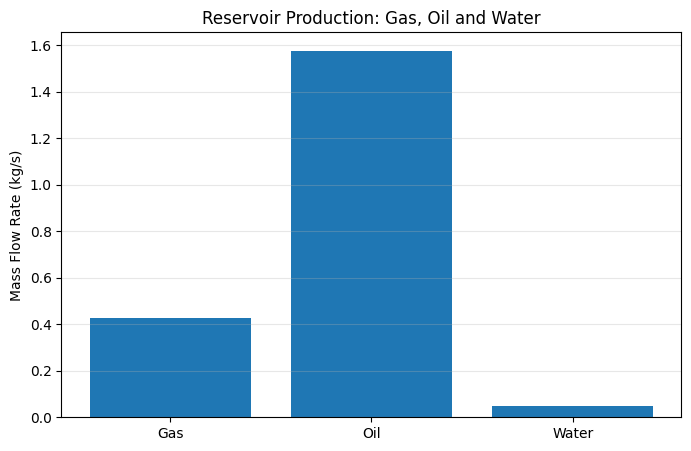

In [36]:
import matplotlib.pyplot as plt

streams = ['Gas', 'Oil', 'Water']
flows = [0.427508, 1.577140, 0.047281]

plt.figure(figsize=(8,5))
plt.bar(streams, flows)
plt.ylabel('Mass Flow Rate (kg/s)')
plt.title('Reservoir Production: Gas, Oil and Water')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [38]:
import pandas as pd

total = sum(flows)

production_summary = pd.DataFrame({
    'Stream': streams,
    'Mass Flow (kg/s)': flows,
    'Production (%)': [
        (x / total) * 100 for x in flows
    ]
})

display(production_summary.round(3))

,Stream,Mass Flow (kg/s),Production (%)
0,Gas,0.428,20.834
1,Oil,1.577,76.861
2,Water,0.047,2.304


In [42]:
!pip install -q plotly

In [43]:
import numpy as np
import plotly.graph_objects as go

# 3D Three-Phase Production Separator
fig = go.Figure()

# Vessel dimensions
radius = 1.0
length = 5.0

# Create cylindrical vessel surface
theta = np.linspace(0, 2*np.pi, 60)
x = np.linspace(-length/2, length/2, 60)
T, X = np.meshgrid(theta, x)

Y = radius * np.cos(T)
Z = radius * np.sin(T)

fig.add_trace(go.Surface(
    x=X, y=Y, z=Z,
    opacity=0.22,
    colorscale="Greys",
    showscale=False,
    name="Separator vessel"
))

# Internal fluid layers
def add_layer(z_bottom, z_top, color, name):
    theta = np.linspace(0, 2*np.pi, 50)
    x = np.linspace(-2.35, 2.35, 50)
    T, X = np.meshgrid(theta, x)

    Y = 0.88 * np.cos(T)
    Z = z_bottom + (z_top-z_bottom) * (
        0.5 + 0.5*np.sin(T)
    )

    fig.add_trace(go.Surface(
        x=X, y=Y, z=Z,
        colorscale=[[0, color], [1, color]],
        showscale=False,
        opacity=0.75,
        name=name,
        showlegend=True
    ))

# Simplified internal separation zones
add_layer(-0.88, -0.30, "#2563eb", "Water zone")
add_layer(-0.30, 0.25, "#d97706", "Oil zone")
add_layer(0.25, 0.88, "#93c5fd", "Gas zone")

# Inlet pipe
fig.add_trace(go.Scatter3d(
    x=[-3.2, -2.35],
    y=[0, 0],
    z=[0, 0],
    mode="lines",
    line=dict(color="black", width=10),
    name="Feed inlet"
))

# Gas outlet
fig.add_trace(go.Scatter3d(
    x=[1.0, 1.0],
    y=[0, 0],
    z=[0.88, 1.65],
    mode="lines+text",
    line=dict(color="#2563eb", width=10),
    text=["", "GAS OUT"],
    textposition="top center",
    name="Gas outlet"
))

# Oil outlet
fig.add_trace(go.Scatter3d(
    x=[2.35, 3.1],
    y=[0, 0],
    z=[-0.05, -0.05],
    mode="lines+text",
    line=dict(color="#d97706", width=10),
    text=["", "OIL OUT"],
    textposition="middle right",
    name="Oil outlet"
))

# Water outlet
fig.add_trace(go.Scatter3d(
    x=[-1.0, -1.0],
    y=[0, 0],
    z=[-0.88, -1.65],
    mode="lines+text",
    line=dict(color="#2563eb", width=10),
    text=["", "WATER OUT"],
    textposition="bottom center",
    name="Water outlet"
))

fig.update_layout(
    title="3D THREE-PHASE PRODUCTION SEPARATOR",
    scene=dict(
        xaxis_title="Length",
        yaxis_title="Width",
        zaxis_title="Height",
        aspectmode="data"
    ),
    template="plotly_white",
    width=1000,
    height=700,
    legend=dict(x=0.02, y=0.98)
)

fig.show()

In [44]:
import numpy as np
import plotly.graph_objects as go

fig = go.Figure()

# Vessel dimensions
L = 5.0
R = 1.0

# 1. Transparent steel cylindrical shell
theta = np.linspace(0, 2*np.pi, 100)
x = np.linspace(-L/2, L/2, 100)
T, X = np.meshgrid(theta, x)

Y = R * np.cos(T)
Z = R * np.sin(T)

fig.add_trace(go.Surface(
    x=X, y=Y, z=Z,
    surfacecolor=np.zeros_like(X),
    colorscale=[[0, "#94a3b8"], [1, "#94a3b8"]],
    opacity=0.22,
    showscale=False,
    name="Steel vessel"
))

# 2. Rounded elliptical vessel heads
phi = np.linspace(0, np.pi, 50)
theta = np.linspace(0, 2*np.pi, 80)
P, T = np.meshgrid(phi, theta)

for side in [-1, 1]:
    hx = side * (L/2 + 0.45*np.sin(P)*np.cos(T))
    hy = 0.95*np.sin(P)*np.sin(T)
    hz = 0.95*np.cos(P)

    fig.add_trace(go.Surface(
        x=hx, y=hy, z=hz,
        colorscale=[[0, "#64748b"], [1, "#64748b"]],
        opacity=0.35,
        showscale=False,
        name="Elliptical vessel head",
        showlegend=False
    ))

# 3. Internal fluid levels (conceptual layers)
xx = np.linspace(-2.35, 2.35, 80)
yy = np.linspace(-0.9, 0.9, 50)
XX, YY = np.meshgrid(xx, yy)

inside = YY**2 <= R**2

# Water layer
water_z = np.full_like(XX, -0.55)
water_z[~inside] = np.nan

fig.add_trace(go.Surface(
    x=XX, y=YY, z=water_z,
    colorscale=[[0, "#1565c0"], [1, "#1565c0"]],
    showscale=False, opacity=0.75,
    name="Water zone"
))

# Oil layer
oil_z = np.full_like(XX, 0.0)
oil_z[~inside] = np.nan

fig.add_trace(go.Surface(
    x=XX, y=YY, z=oil_z,
    colorscale=[[0, "#d97706"], [1, "#d97706"]],
    showscale=False, opacity=0.75,
    name="Oil zone"
))

# 4. Inlet nozzle
fig.add_trace(go.Scatter3d(
    x=[-3.4, -2.35], y=[0, 0], z=[0, 0],
    mode="lines",
    line=dict(color="#334155", width=13),
    name="Production inlet"
))

# 5. Gas outlet
fig.add_trace(go.Scatter3d(
    x=[0.8, 0.8], y=[0, 0], z=[0.75, 1.65],
    mode="lines+text",
    line=dict(color="#2563eb", width=12),
    text=["", "GAS OUT"],
    textposition="top center",
    name="Gas outlet"
))

# 6. Oil outlet
fig.add_trace(go.Scatter3d(
    x=[2.3, 3.1], y=[0, 0], z=[-0.05, -0.05],
    mode="lines+text",
    line=dict(color="#d97706", width=12),
    text=["", "OIL OUT"],
    textposition="middle right",
    name="Oil outlet"
))

# 7. Water outlet
fig.add_trace(go.Scatter3d(
    x=[-1.2, -1.2], y=[0, 0], z=[-0.8, -1.6],
    mode="lines+text",
    line=dict(color="#1565c0", width=12),
    text=["", "WATER OUT"],
    textposition="bottom center",
    name="Water outlet"
))

fig.update_layout(
    title=dict(
        text="3D THREE-PHASE PRODUCTION SEPARATOR",
        x=0.5
    ),
    template="plotly_white",
    width=1100,
    height=750,
    scene=dict(
        xaxis_title="Vessel Length",
        yaxis_title="Vessel Width",
        zaxis_title="Vessel Height",
        aspectmode="data",
        camera=dict(eye=dict(x=1.7, y=1.7, z=1.2))
    )
)

fig.show()

In [45]:
import numpy as np
import plotly.graph_objects as go

fig = go.Figure()

# Vessel dimensions
L = 5.0
R = 1.0

# Fluid interface elevations
water_level = -0.45
oil_level = 0.15

# Transparent cylindrical steel shell
theta = np.linspace(0, 2*np.pi, 100)
x = np.linspace(-L/2, L/2, 100)
T, X = np.meshgrid(theta, x)

fig.add_trace(go.Surface(
    x=X,
    y=R*np.cos(T),
    z=R*np.sin(T),
    colorscale=[[0, "#64748b"], [1, "#64748b"]],
    opacity=0.15,
    showscale=False,
    name="Transparent steel shell"
))

# Draw curved internal zones
def add_zone(theta_start, theta_end, color, name):
    angles = np.linspace(theta_start, theta_end, 50)
    positions = np.linspace(-L/2, L/2, 70)
    A, X = np.meshgrid(angles, positions)

    fig.add_trace(go.Surface(
        x=X,
        y=R*np.cos(A),
        z=R*np.sin(A),
        colorscale=[[0, color], [1, color]],
        opacity=0.75,
        showscale=False,
        name=name
    ))

# Water: bottom curved section
add_zone(-np.pi/2, np.arcsin(water_level/R),
         "#1565C0", "Water zone")

# Oil: middle curved section
add_zone(np.arcsin(water_level/R),
         np.arcsin(oil_level/R),
         "#D97706", "Oil zone")

# Gas: upper curved section
add_zone(np.arcsin(oil_level/R), np.pi/2,
         "#7DD3FC", "Gas zone")

# Flat liquid interface surfaces
def add_interface(level, color, name):
    width = np.sqrt(R**2 - level**2)
    xx = np.linspace(-L/2, L/2, 60)
    yy = np.linspace(-width, width, 40)
    XX, YY = np.meshgrid(xx, yy)

    fig.add_trace(go.Surface(
        x=XX,
        y=YY,
        z=np.full_like(XX, level),
        colorscale=[[0, color], [1, color]],
        opacity=0.8,
        showscale=False,
        name=name
    ))

add_interface(water_level, "#2563EB", "Water-oil interface")
add_interface(oil_level, "#D97706", "Oil-gas interface")

# Feed inlet
fig.add_trace(go.Scatter3d(
    x=[-3.4, -2.5],
    y=[0, 0],
    z=[0, 0],
    mode="lines+text",
    line=dict(color="black", width=10),
    text=["", "FEED INLET"],
    textposition="bottom left",
    name="Feed inlet"
))

# Gas outlet
fig.add_trace(go.Scatter3d(
    x=[0.8, 0.8],
    y=[0, 0],
    z=[0.9, 1.6],
    mode="lines+text",
    line=dict(color="#0284C7", width=10),
    text=["", "GAS OUT"],
    textposition="top center",
    name="Gas outlet"
))

# Oil outlet
fig.add_trace(go.Scatter3d(
    x=[2.3, 3.1],
    y=[0, 0],
    z=[0, 0],
    mode="lines+text",
    line=dict(color="#D97706", width=10),
    text=["", "OIL OUT"],
    textposition="middle right",
    name="Oil outlet"
))

# Water outlet
fig.add_trace(go.Scatter3d(
    x=[-1.2, -1.2],
    y=[0, 0],
    z=[-0.9, -1.6],
    mode="lines+text",
    line=dict(color="#1565C0", width=10),
    text=["", "WATER OUT"],
    textposition="bottom center",
    name="Water outlet"
))

fig.update_layout(
    title="3D HORIZONTAL THREE-PHASE SEPARATOR",
    template="plotly_white",
    width=1100,
    height=750,
    scene=dict(
        xaxis_title="Vessel Length",
        yaxis_title="Vessel Width",
        zaxis_title="Vessel Height",
        aspectmode="data",
        camera=dict(eye=dict(x=1.7, y=1.7, z=1.2))
    )
)

fig.show()

In [46]:
# Add two conceptual separator internals to the existing figure

# 1. Inlet diverter plate
fig.add_trace(go.Mesh3d(
    x=[-1.95, -1.65, -1.65, -1.95],
    y=[-0.65, -0.65, 0.65, 0.65],
    z=[-0.55, 0.55, 0.55, -0.55],
    i=[0, 0], j=[1, 2], k=[2, 3],
    color="#64748b",
    opacity=0.9,
    name="Inlet diverter"
))

# 2. Mist eliminator pad near gas outlet
x_pad = np.linspace(1.35, 1.65, 8)
y_pad = np.linspace(-0.65, 0.65, 8)
X_pad, Y_pad = np.meshgrid(x_pad, y_pad)
Z_pad = np.full_like(X_pad, 0.72)

fig.add_trace(go.Surface(
    x=X_pad,
    y=Y_pad,
    z=Z_pad,
    colorscale=[[0, "#16a34a"], [1, "#16a34a"]],
    showscale=False,
    opacity=0.9,
    name="Mist eliminator"
))

# 3. Add equipment annotations
fig.add_trace(go.Scatter3d(
    x=[-1.8, 1.5],
    y=[0, 0],
    z=[0.75, 0.95],
    mode="text",
    text=["INLET DIVERTER", "MIST ELIMINATOR"],
    textposition="top center",
    textfont=dict(size=11, color="black"),
    name="Internal equipment labels"
))

fig.update_layout(
    title="3D THREE-PHASE SEPARATOR WITH INTERNAL EQUIPMENT"
)

fig.show()

In [47]:
# DWSIM calculated outlet mass flows (kg/s)
gas_flow = 0.427508
oil_flow = 1.577140
water_flow = 0.0472813

total_flow = gas_flow + oil_flow + water_flow

# Add a results panel beside the 3D separator
fig.add_trace(go.Scatter3d(
    x=[3.3, 3.3, 3.3, 3.3],
    y=[0, 0, 0, 0],
    z=[1.1, 0.45, -0.2, -0.9],
    mode="text",
    text=[
        "DWSIM RESULTS",
        f"GAS: {gas_flow:.6f} kg/s",
        f"OIL: {oil_flow:.6f} kg/s",
        f"WATER: {water_flow:.6f} kg/s"
    ],
    textfont=dict(size=12, color="black"),
    name="DWSIM mass flow results"
))

# Add total mass flow separately
fig.add_trace(go.Scatter3d(
    x=[3.3],
    y=[0],
    z=[-1.4],
    mode="text",
    text=[f"TOTAL: {total_flow:.6f} kg/s"],
    textfont=dict(size=13, color="darkgreen"),
    name="Total mass flow"
))

fig.update_layout(
    title="3D THREE-PHASE SEPARATOR | DWSIM RESULTS",
    width=1200,
    height=800
)

fig.show()

In [48]:
# DWSIM outlet results
gas = 0.427508
oil = 1.577140
water = 0.0472813

total = gas + oil + water

# Calculate outlet mass percentages
gas_pct = gas / total * 100
oil_pct = oil / total * 100
water_pct = water / total * 100

# Remove old 3D results labels to avoid duplication
fig.data = tuple(
    trace for trace in fig.data
    if trace.name not in [
        "DWSIM mass flow results",
        "Total mass flow"
    ]
)

# Position 3D separator on the left
fig.update_layout(
    width=1250,
    height=780,
    title="THREE-PHASE PRODUCTION SEPARATOR | DWSIM RESULTS",
    scene=dict(
        domain=dict(x=[0, 0.68], y=[0.05, 0.95]),
        camera=dict(eye=dict(x=1.7, y=1.7, z=1.2))
    ),
    margin=dict(l=10, r=20, t=90, b=30)
)

# Add results panel background
fig.add_shape(
    type="rect",
    xref="paper", yref="paper",
    x0=0.72, x1=0.99,
    y0=0.12, y1=0.90,
    fillcolor="#f1f5f9",
    line=dict(color="#64748b", width=1)
)

# Add engineering results
results = [
    (0.83, "DWSIM OUTLET RESULTS", 17, "#0f172a"),
    (0.70, f"GAS: {gas:.6f} kg/s", 13, "#0284c7"),
    (0.59, f"OIL: {oil:.6f} kg/s", 13, "#b45309"),
    (0.48, f"WATER: {water:.6f} kg/s", 13, "#1d4ed8"),
    (0.34, f"TOTAL: {total:.6f} kg/s", 14, "#166534"),
    (0.22, "MASS FRACTIONS", 13, "#0f172a"),
    (0.15, f"Gas {gas_pct:.2f}% | Oil {oil_pct:.2f}% | Water {water_pct:.2f}%", 10, "#334155")
]

for y, label, size, color in results:
    fig.add_annotation(
        x=0.855, y=y,
        xref="paper", yref="paper",
        text=label,
        showarrow=False,
        font=dict(size=size, color=color),
        align="center"
    )

fig.show()

In [51]:
!pip install -q kaleido